In [1]:
import pandas as pd
from subprocess import Popen, PIPE
import time
import numpy as np
import matplotlib.pyplot as plt


# Data preprocessing

In [2]:
#  load data
df1 = pd.read_csv("../account_inf/hate_groups - Religious Right.tsv",sep='\t')
df2 = pd.read_csv("../account_inf/hate_groups - SPLC Hate Groups.tsv",sep='\t')
print(df1.shape,df2.shape)
# fillna with ''
df1 = df1.fillna('')
df2 = df2.fillna('')
# strip interested columns : Twitter & politician
df1.Twitter = df1.Twitter.apply(lambda x: x.strip())
df1.politician = df1.politician.apply(lambda x: x.strip())
df2.Twitter = df2.Twitter.apply(lambda x: x.strip())
df2.politician = df2.politician.apply(lambda x: x.strip())
# remove Twitter = ""
df1 = df1[df1.Twitter !=''].reset_index(drop=True)
df2 = df2[df2.Twitter !=''].reset_index(drop=True)

print(df1.shape,df2.shape)

(206, 7) (92, 7)
(206, 7) (86, 7)


In [4]:
overlapped_account_list = list(set(list(df1.Twitter.values))&set(list(df2.Twitter.values)))
print("Overlapped account: ",overlapped_account_list)

Overlapped account:  ['@ACTBrigitte']


In [5]:
df1[df1.Twitter==overlapped_account_list[0]]

,Twitter,Description,group,Notes,Source ABCD,L/R?,politician
121,@ACTBrigitte,"Founder and Chairman of ACT For America, Author",NGO,A,2019 Values Voer Summit Speaker,,


In [6]:
df2[df2.Twitter==overlapped_account_list[0]]

,Twitter,Group,Description,Category,Listed/Related,Notes,politician
23,@ACTBrigitte,,Founder of ACT for America,anti-muslim,,,


In [24]:
name_right = list(set(df1.Twitter.values))
name_right =  [name[1:] for name in name_right if name[0]=='@']
name_hate = list(set(df2.Twitter.values))
name_hate =  [name[1:] for name in name_hate if name[0]=='@']

# if you uncomment the below line, you will compare "tagged hate" with "right"
# you will compare "hate" with "right";

# name_hate = ['AlM_AMERlCA',
#  'vdare',
#  'peterbrimelow',
#  'pioneer_fund',
#  'PatriotFront',
#  'RADIXJournal_',
#  'PissoffEU',
#  'JamesEdwardsTPC',
#  'TOOedit',
#  'TheAFP2018',
#  'LeagueOfSouth',
#  'NatReformation',
#  'WhiteGenocide',
#  '901Confederate',
#  'amsance2015',
#  'RenaissanceHor1',
#  'KyleBristow',
#  'ProudBoysUS',
#  'Thedailystormer',
#  'identitydixie1',
#  'antelopehill',
#  'NewRightAmerica',
#  'aim_america',
#  'NationVanguard']
name_group_dict = dict(zip(name_right+name_hate,['religious-right']*len(name_right)+['hate']*len(name_hate)))

In [25]:
# all_name = list(set(list(df1.Twitter.values)+list(df2.Twitter.values)))
# all_name = [name[1:] for name in all_name if name[0]=='@']
all_name = name_right+name_hate
print("original names: ",df1.shape[0]+df2.shape[0])
print("unique names: ",len(all_name))

original names:  292
unique names:  276


In [57]:
# sort names
all_name= sorted(all_name)

In [58]:
# importing the module
import json
id_list = []
text_list = []
name_list = []
# Opening JSON file
m =0
for j in range(len(all_name)):
    try:
        with open('%s.json'%all_name[j]) as f:
            s=f.readlines()
        m+=1
    except:
        continue
    for i in range(len(s)):
        d = json.loads(s[i][:-1])
        try:
            id_list.append(d['id'])
            text_list.append(d['text'])
            
            name_list.append(all_name[j])
        except:
            continue
    


In [ ]:
df_tweet = pd.DataFrame({"tweet_id":id_list,"text":text_list, "author": name_list})
df_tweet['group'] = df_tweet['author'].map(name_group_dict)

# Visualization

In [60]:
def extract_hashtag(text_list):
    all_text = ' '.join(text_list)
    tokens = all_text.split()
    hashtag = [ word[1:] for word in tokens if word[0]=='#' and len(word)>1]
    return hashtag
def extract_retweet_origin(text_list):
    all_text = ' '.join(text_list)
    tokens = all_text.split()
    retw = all_text.split("RT @")[1:]
    RT_list = [name.split(':')[0] for name in retw ]
    return RT_list
def top_hashtag(hashtag,k):
    hash_ct = np.unique(hashtag,return_counts = True)
    idx  = np.argsort(hash_ct[1])[::-1]
    y_values = hash_ct[0][idx][:k]
    return y_values
#     plt.show()
def hashtag_bar(hashtag, title_text,common_hashtag,k):
    hash_ct = np.unique(hashtag,return_counts = True)
    idx  = np.argsort(hash_ct[1])[::-1]


    x_values = 100*hash_ct[1][idx][:k]/sum(hash_ct[1])
    x_values = hash_ct[1][idx][:k]
    y_values = hash_ct[0][idx][:k]
    y_color = [ 'orange' if ht in common_hashtag else 'navy' for ht in y_values ]
    y_axis = np.arange( len(y_values)+1,1, -1)

    f = plt.figure()
    f.set_figwidth(4)
    f.set_figheight(8)
    plt.barh(y_axis, x_values, align='center',color = y_color)
    plt.yticks(y_axis, y_values)
#     plt.xlabel("percent(%)",fontsize=18,fontname = "Adobe Caslon Pro")
    plt.xlabel("count",fontsize=18,fontname = "Adobe Caslon Pro")
    
#     plt.ylabel("hashtag",fontsize=18)
    plt.title(title_text, fontname='Comic Sans MS', fontsize=18)
    return plt,y_values
    

common hashtags:  {'China', 'Jesus', 'MLKDay', 'China’s', 'Capitol', 'Democrat', 'MLK', '…', 'Newsmax', 'censorship', 'CapitolRiots', 'MLKDay2021', 'Georgia', 'StopTheSteal', 'stopthesteal', 'Antifa', 'MAGA', 'AmericaFirst', 'COVID19', 'GOP', 'impeachment', 'Biden', 'CapitolBuilding', 'Trump', 'ElectoralCollege', '1', 'Election2020', 'FoxNews', 'BigTech', 'CCP', 'BLM', 'gapol', 'January6th', 'Unbelievable', 'GASen', 'BREAKING:', 'Iran', 'HumanTraffickingAwarenessDay', 'JAN6', 'Israel', 'StopTheSteaI', 'NorthKorea'}


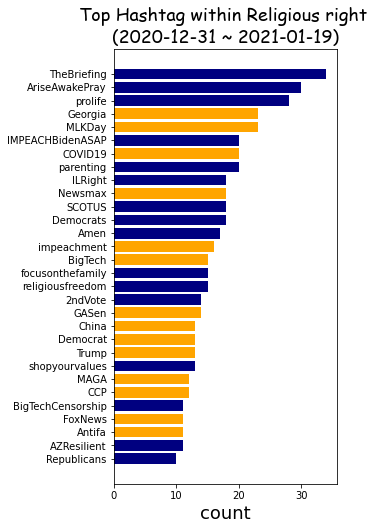

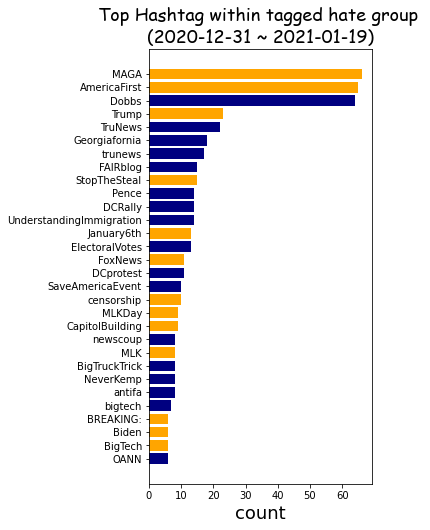

In [61]:
text_list_right = df_tweet[df_tweet.group == 'religious-right'].text.tolist()
text_list_hate = df_tweet[df_tweet.group != 'religious-right'].text.tolist()
hashtag_right_list = extract_hashtag(text_list_right)
hashtag_hate_list = extract_hashtag(text_list_hate)
top30_right = top_hashtag(hashtag_right_list,k=200)
top30_hate = top_hashtag(hashtag_hate_list,k=200)
common_hash = set(top30_right)&set(top30_hate)
print("common hashtags: ",common_hash)
plt_right = hashtag_bar(hashtag_right_list,
                        "Top Hashtag within Religious right \n(2020-12-31 ~ 2021-01-19)",
                        common_hash,
                       k=30)
# plt_right.show()
plt_hate = hashtag_bar(hashtag_hate_list, 
                       "Top Hashtag within tagged hate group \n(2020-12-31 ~ 2021-01-19)",
                       common_hash,
                      k=30)
# plt_hate.show()

common information source:  {'NoahCRothman', 'RubinReport', 'RepMattGaetz', 'charliekirk11', 'TheBabylonBee', 'HawleyMO', 'JackPosobiec', 'ColumbiaBugle', 'guypbenson', 'benshapiro', 'newsmax', 'thehill', 'SohrabAhmari', 'KurtSchlichter', 'JennaEllisEsq', 'seanhannity', 'ksorbs', 'TrumpWarRoom', 'SecPompeo', 'michellemalkin', 'Annakhait', 'DavidJHarrisJr', 'RepMoBrooks', 'tedcruz', 'CortesSteve', 'DineshDSouza', 'MZHemingway', 'TomFitton', 'ACTBrigitte', 'MrAndyNgo', 'michaeljknowles', 'GOPLeader', 'neontaster', 'jsolomonReports', 'ByronYork', 'Jim_Jordan', 'kayleighmcenany', 'gregkellyusa', 'SaraCarterDC', 'RichardGrenell', 'MattWalshBlog', 'EWErickson', 'IngrahamAngle', 'GeorgePapa19', 'robbystarbuck', 'JasonMillerinDC', 'EmeraldRobinson', 'AnnCoulter', 'DonaldJTrumpJr', 'DailyCaller', 'RaheemKassam', 'mtracey', 'RealKyleMorris', 'HerschelWalker', 'AGHamilton29', 'KatiePavlich', 'KLoeffler', 'ggreenwald', 'RudyGiuliani', 'laurenboebert', 'RealCandaceO'}


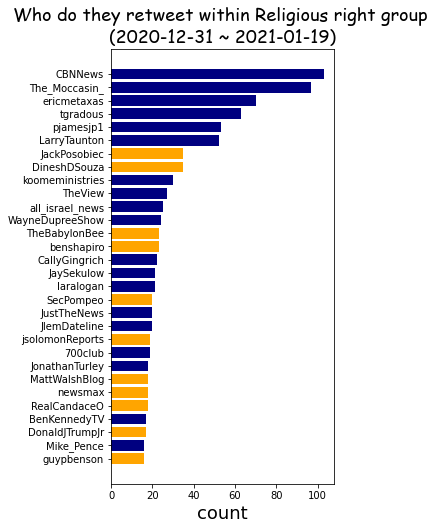

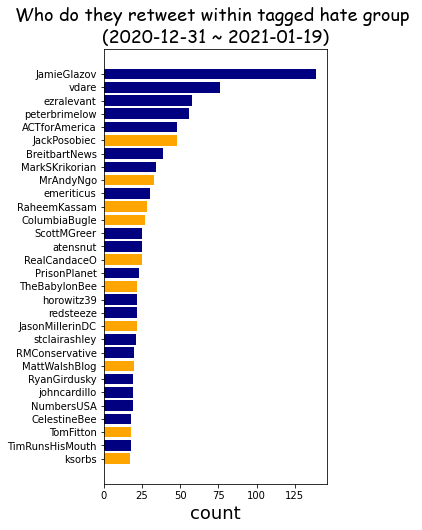

In [62]:
hashtag_right_list = extract_retweet_origin(text_list_right)
hashtag_hate_list = extract_retweet_origin(text_list_hate)
top30_right = top_hashtag(hashtag_right_list,k=200)
top30_hate = top_hashtag(hashtag_hate_list,k=200)
common_hash = set(top30_right)&set(top30_hate)
print("common information source: ",common_hash)
plt_right = hashtag_bar(hashtag_right_list,
                        "Who do they retweet within Religious right group \n(2020-12-31 ~ 2021-01-19)",
                        common_hash,
                       k=30)
# plt_right.show()
plt_hate = hashtag_bar(hashtag_hate_list, 
                       "Who do they retweet within tagged hate group \n(2020-12-31 ~ 2021-01-19)",
                       common_hash,
                      k=30)

In [37]:
id_list = [int(id) for id in id_list]
name_tweet_dict = dict(zip(id_list,name_list))
df_rt = pd.read_csv("retweet.txt")
df_rt['author'] = df_rt['tweet_id'].map(name_tweet_dict)  
df_rt['group'] = df_rt['author'].map(name_group_dict) 
id_text_dict = dict(zip(id_list,text_list))
df_rt ['text'] = df_rt.tweet_id.map(id_text_dict)
df_rt = df_rt.dropna().reset_index()

In [63]:
retweeter_of_right  = df_rt[df_rt.group =='religious-right'].user_id.unique()
retweeter_of_hate  = df_rt[df_rt.group !='religious-right'].user_id.unique()
print("number of users who only retweet right group : ",len(retweeter_of_right )-len(set(retweeter_of_right)&set(retweeter_of_hate)))
print("number of users who only retweet hate group : ",len(retweeter_of_hate )-len(set(retweeter_of_right)&set(retweeter_of_hate)))
print("number of users who retweet both groups:", len(set(retweeter_of_right)&set(retweeter_of_hate)))

number of users who only retweet right group :  30376
number of users who only retweet hate group :  15308
number of users who retweet both groups: 5078


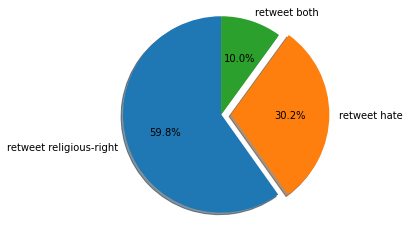

In [47]:
import matplotlib.pyplot as plt

# Pie chart, where the slices will be ordered and plotted counter-clockwise:
labels = 'retweet religious-right', 'retweet hate', 'retweet both'
sizes = [len(retweeter_of_right )-len(set(retweeter_of_right)&set(retweeter_of_hate)),
        len(retweeter_of_hate )-len(set(retweeter_of_right)&set(retweeter_of_hate)),
        len(set(retweeter_of_right)&set(retweeter_of_hate))]
explode = (0, 0.1, 0)  # only "explode" the 2nd slice (i.e. 'Hogs')

fig1, ax1 = plt.subplots()
ax1.pie(sizes, explode=explode, labels=labels, autopct='%1.1f%%',
        shadow=True, startangle=90)
ax1.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
# plt.savefig('plot/retweeter_pie.pdf')  # saves the current figure into a pdf page
plt.show()
plt.close()

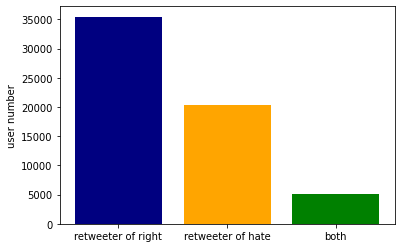

In [48]:
# libraries
import numpy as np
import matplotlib.pyplot as plt
# with PdfPages('plot/retweeter_bar.pdf') as pdf:
# create a dataset
height = [len(retweeter_of_right ),
            len(retweeter_of_hate ),
            len(set(retweeter_of_right)&set(retweeter_of_hate))]
bars = ('retweeter of right', 'retweeter of hate', 'both')
x_pos = np.arange(len(bars))

# Create bars with different colors
plt.bar(x_pos, height, color=['navy','orange',"green"])
plt.ylabel("user number")
# Create names on the x-axis
plt.xticks(x_pos, bars)

# Show graph
# pdf.savefig()  # saves the current figure into a pdf page

plt.show()
plt.close()